# Advanced EDA & Feature Engineering: Raw Orders → ML-Ready Dataset

**Dataset:** 1,200 e-commerce orders, 14 columns.
**Pipeline:** Load → Audit → EDA → Missing data → Outliers → Feature engineering → Encoding → Split & scale → Save


## Summary of the project
- Audited and type-corrected the data; validated TotalPrice = Quantity × UnitPrice
- Treated structural missingness (CouponCode) correctly and benchmarked Mean / Median / KNN imputation
- Detected outliers with IQR and Z-score; neutralised them by capping and log transform
- Engineered 14 new features from existing columns
- Encoded, split, scaled (leak-free), validated and exported the dataset

#### Import of libraries, loading of data 

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams["figure.figsize"] = (8, 4)
RANDOM_STATE = 42

df_raw = pd.read_csv("Dataset.csv")
df = df_raw.copy()          # never modify the raw data; always work on a copy
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.620,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,"2,853.100"
1,ORD200001,2024-08-23,C75739,Phone,2,151.350,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.700
2,ORD200002,2024-02-27,C81728,Tablet,5,550.680,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,"2,753.400"
3,ORD200003,2023-10-15,C33540,Chair,1,273.190,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.190
4,ORD200004,2025-05-08,C81840,Printer,4,626.010,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,"2,504.040"


#### Data audit
 - Checking data size, data types, missing data, and duplicated data

In [8]:
print("Shape:", df.shape)
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate OrderIDs:", df["OrderID"].duplicated().sum())

audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
audit

Shape: (1200, 14)

Duplicate rows: 0
Duplicate OrderIDs: 0


,dtype,n_missing,pct_missing,n_unique
OrderID,object,0,0.000,1200
Date,object,0,0.000,671
CustomerID,object,0,0.000,1189
Product,object,0,0.000,7
Quantity,int64,0,0.000,5
UnitPrice,float64,0,0.000,1193
ShippingAddress,object,0,0.000,655
PaymentMethod,object,0,0.000,5
OrderStatus,object,0,0.000,5
TrackingNumber,object,0,0.000,1200


**What we notice**
- Only `CouponCode` has missing values.
- `OrderID`, `TrackingNumber` are unique per row → identifiers, not predictive.
- `Date` is stored as text → should become a real datetime.

## Fixing data types and validating business logic

In [9]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Unparseable dates:", df["Date"].isna().sum())
print("Date range:", df["Date"].min().date(), "->", df["Date"].max().date())

# Business rule: TotalPrice should equal Quantity * UnitPrice
expected = (df["Quantity"] * df["UnitPrice"]).round(2)
mismatch = ~np.isclose(expected, df["TotalPrice"], atol=0.02)
print("Rows where TotalPrice != Quantity*UnitPrice:", mismatch.sum())

# Another rule: you cannot buy more units than items in the cart
print("Rows where Quantity > ItemsInCart:", (df["Quantity"] > df["ItemsInCart"]).sum())

Unparseable dates: 0
Date range: 2023-01-01 -> 2025-06-30
Rows where TotalPrice != Quantity*UnitPrice: 0
Rows where Quantity > ItemsInCart: 0


> **Finding:** `TotalPrice` is *exactly* `Quantity × UnitPrice`. So if you ever predict `TotalPrice`, you must drop `Quantity` and `UnitPrice` (or vice versa), or the model just learns the formula (**data leakage**).

## Exploratory Data Analysis (EDA)

### Numeric variables: distribution, skew, spread

In [10]:
num_cols = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]
summary = df[num_cols].describe().T
summary["skew"] = df[num_cols].skew()
summary["kurtosis"] = df[num_cols].kurt()
summary

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Quantity,"1,200.000",2.946,1.408,1.000,2.000,3.000,4.000,5.000,0.028,-1.295
UnitPrice,"1,200.000",356.413,197.177,11.390,186.062,364.210,521.570,699.930,-0.027,-1.191
ItemsInCart,"1,200.000",5.485,2.282,1.000,4.000,5.000,7.000,10.000,0.001,-0.709
TotalPrice,"1,200.000","1,053.968",819.857,11.390,410.520,823.615,"1,578.475","3,456.400",0.891,-0.040


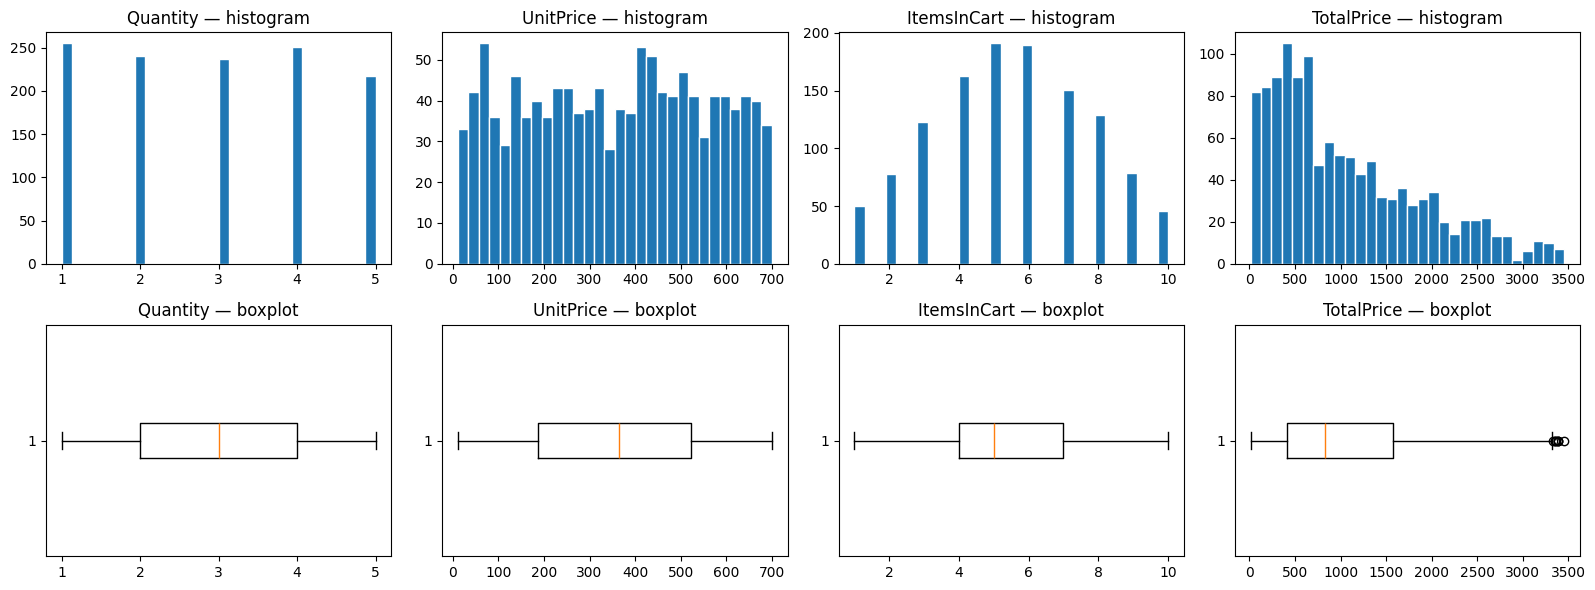

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for i, c in enumerate(num_cols):
    axes[0, i].hist(df[c], bins=30, edgecolor="white")
    axes[0, i].set_title(f"{c} — histogram")
    axes[1, i].boxplot(df[c], vert=False)
    axes[1, i].set_title(f"{c} — boxplot")
plt.tight_layout(); plt.show()

`TotalPrice` is right-skewed (a product of two variables is almost always skewed) and is the only numeric column with boxplot outliers. 

### Categorical variables

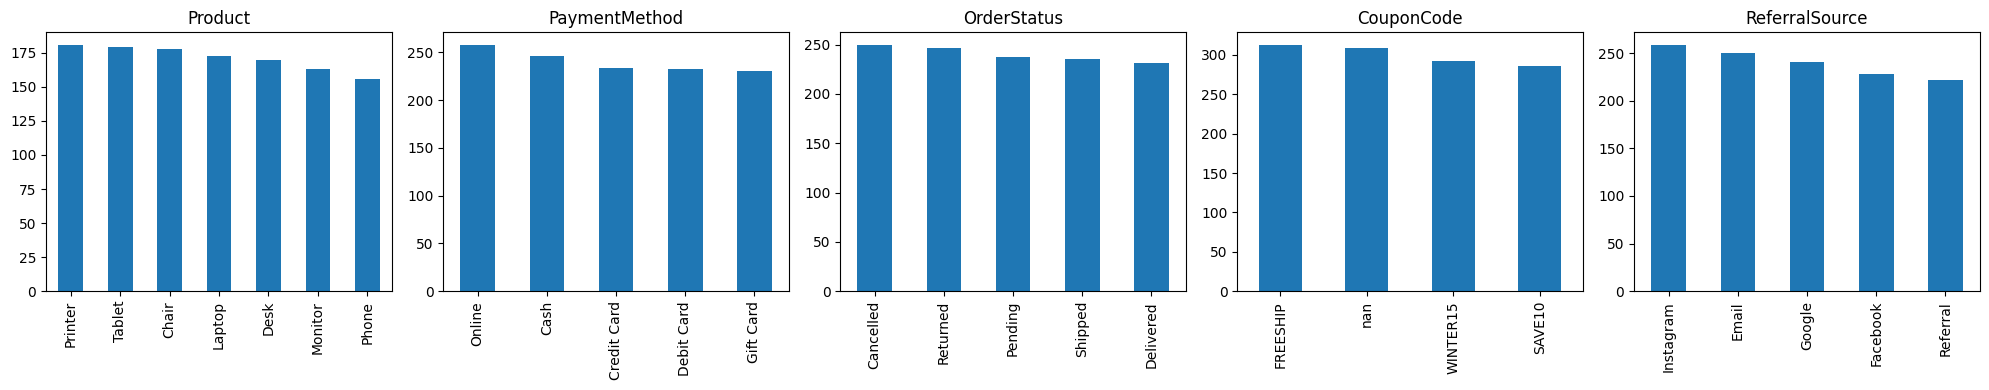

In [12]:
cat_cols = ["Product", "PaymentMethod", "OrderStatus", "CouponCode", "ReferralSource"]
fig, axes = plt.subplots(1, len(cat_cols), figsize=(20, 4))
for ax, c in zip(axes, cat_cols):
    df[c].value_counts(dropna=False).plot(kind="bar", ax=ax, title=c)
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

### 3c. Relationships: time trend, groups, correlation

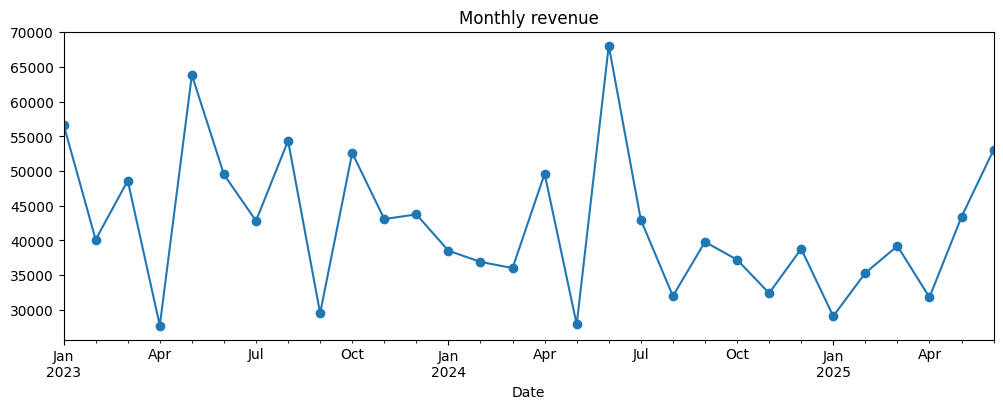

Average order value by product:


,count,mean,median
Product,,,
Laptop,173,"1,110.558",915.640
Chair,178,"1,098.989",928.575
Printer,181,"1,080.733",857.400
Monitor,163,"1,077.616",853.400
Tablet,179,"1,042.285",786.660
Desk,170,985.058,784.390
Phone,156,972.579,691.715


Order status share by payment method (row %):


OrderStatus,Cancelled,Delivered,Pending,Returned,Shipped
PaymentMethod,,,,,
Cash,19.900,18.300,21.100,23.200,17.500
Credit Card,23.100,18.400,20.500,20.900,17.100
Debit Card,19.000,18.500,23.700,22.000,16.800
Gift Card,21.700,16.100,15.200,22.600,24.300
Online,20.500,24.400,18.200,14.700,22.100


In [13]:
monthly = df.set_index("Date")["TotalPrice"].resample("ME").agg(["sum", "count"])
fig, ax = plt.subplots(figsize=(12, 4))
monthly["sum"].plot(ax=ax, marker="o", title="Monthly revenue")
plt.show()

print("Average order value by product:")
display(df.groupby("Product")["TotalPrice"].agg(["count", "mean", "median"]).sort_values("mean", ascending=False))

print("Order status share by payment method (row %):")
display(pd.crosstab(df["PaymentMethod"], df["OrderStatus"], normalize="index").mul(100).round(1))

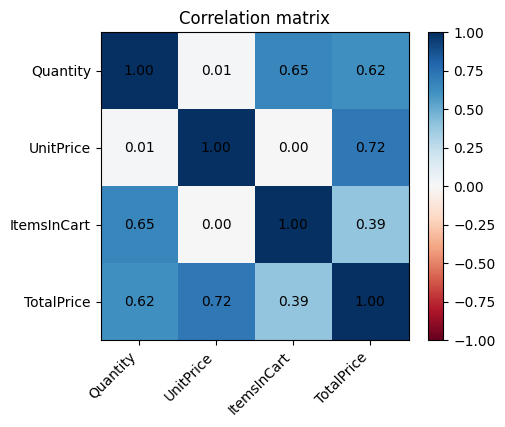

In [14]:
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=45, ha="right")
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im); plt.title("Correlation matrix"); plt.show()

**From the heatmap:** `Quantity` and `UnitPrice` are uncorrelated with each other (~0), and both correlate with `TotalPrice` only because it is their product.

## Missing data

### Understanding why it is missing

In [15]:
print("Missing CouponCode:", df["CouponCode"].isna().sum(), f"({df['CouponCode'].isna().mean():.1%})")
print("\nCoupon values:", df["CouponCode"].value_counts(dropna=False).to_dict())

# Is missingness related to anything? (if 'no coupon' is a real behaviour, it should look random vs other columns)
print("\nShare of orders with no coupon, by OrderStatus:")
display(df.groupby("OrderStatus")["CouponCode"].apply(lambda s: s.isna().mean()).round(3))

Missing CouponCode: 309 (25.8%)

Coupon values: {'FREESHIP': 313, nan: 309, 'WINTER15': 292, 'SAVE10': 286}

Share of orders with no coupon, by OrderStatus:


OrderStatus
Cancelled   0.232
Delivered   0.225
Pending     0.249
Returned    0.308
Shipped     0.272
Name: CouponCode, dtype: float64

**A blank coupon** almost certainly means **"customer used no coupon"** : it is *structural* missingness (a real answer), not lost data. Imputing it with a mean/median/KNN would invent coupons that never existed. it must be labelled explicitly.

In [16]:
df["CouponCode"] = df["CouponCode"].fillna("NoCoupon")
print(df["CouponCode"].value_counts())
print("Remaining missing values:", df.isna().sum().sum())

CouponCode
FREESHIP    313
NoCoupon    309
WINTER15    292
SAVE10      286
Name: count, dtype: int64
Remaining missing values: 0


### Statistical imputation: Mean vs Median vs KNN
The data has **no missing numeric values**, so to demonstrate and *compare* the three methods honestly, we:
1. take the complete numeric columns as ground truth,
2. randomly delete 10% of values,
3. impute with each method,
4. measure which recovers the true values best (normalised RMSE; lower = better).

In [17]:
imp_cols = ["Quantity", "UnitPrice", "ItemsInCart"]
truth = df[imp_cols].copy()

rng = np.random.default_rng(RANDOM_STATE)
mask = pd.DataFrame(rng.random(truth.shape) < 0.10, columns=imp_cols, index=truth.index)
holes = truth.mask(mask)                      # same data with ~10% artificial holes
print("Artificial missing cells:", int(mask.values.sum()))

# KNN works on distances, so give it scaled numeric columns + one-hot Product for extra signal
def knn_impute(frame, k=5):
    ctx = pd.get_dummies(df["Product"], dtype=float)
    X = pd.concat([frame, ctx], axis=1)
    scaler = StandardScaler()
    Xs = scaler.fit_transform(X)              # StandardScaler ignores NaN when fitting
    Xi = KNNImputer(n_neighbors=k).fit_transform(Xs)
    return pd.DataFrame(scaler.inverse_transform(Xi)[:, :frame.shape[1]], columns=frame.columns, index=frame.index)

imputed = {
    "Mean":   pd.DataFrame(SimpleImputer(strategy="mean").fit_transform(holes), columns=imp_cols, index=truth.index),
    "Median": pd.DataFrame(SimpleImputer(strategy="median").fit_transform(holes), columns=imp_cols, index=truth.index),
    "KNN(5)": knn_impute(holes, k=5),
}

def nrmse(pred, true, m):
    out = {}
    for c in true.columns:
        err = (pred.loc[m[c], c] - true.loc[m[c], c])
        out[c] = np.sqrt((err ** 2).mean()) / true[c].std()
    return out

results = pd.DataFrame({name: nrmse(frame, truth, mask) for name, frame in imputed.items()})
results["best"] = results.idxmin(axis=1)
results

Artificial missing cells: 363


,Mean,Median,KNN(5),best
Quantity,1.034,1.035,0.958,KNN(5)
UnitPrice,0.945,0.945,1.027,Mean
ItemsInCart,1.000,1.023,0.882,KNN(5)


NRMSE near 1.0 means the imputer does no better than guessing the average. Here the columns are essentially independent of one another (see the heatmap), so KNN has little to learn from and all three methods perform similarly.

### Reusable imputation function; for furture data

In [18]:
def impute_numeric(frame, cols, strategy="median", k=5):
    """strategy: 'mean' | 'median' | 'knn'. Returns a copy with `cols` imputed."""
    out = frame.copy()
    if out[cols].isna().sum().sum() == 0:
        return out
    if strategy in ("mean", "median"):
        out[cols] = SimpleImputer(strategy=strategy).fit_transform(out[cols])
    elif strategy == "knn":
        sc = StandardScaler()
        out[cols] = sc.inverse_transform(KNNImputer(n_neighbors=k).fit_transform(sc.fit_transform(out[cols])))
    else:
        raise ValueError("strategy must be mean, median or knn")
    return out

df = impute_numeric(df, ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"], strategy="median")
assert df.isna().sum().sum() == 0, "Still have missing values!"
print("✔ Dataset has zero missing values")

✔ Dataset has zero missing values


## Outliers: detect with IQR and Z-score, then neutralise

- **IQR rule:** flag values outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`. Robust, no normality assumption.
- **Z-score rule:** flag `|z| > 3`. Assumes roughly bell-shaped data and is itself distorted by outliers.

In [19]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for c in ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]:
    lo, hi = iqr_bounds(df[c])
    z = np.abs(stats.zscore(df[c]))
    rows.append({"column": c, "IQR_lower": lo, "IQR_upper": hi,
                 "IQR_outliers": int(((df[c] < lo) | (df[c] > hi)).sum()),
                 "Z>3_outliers": int((z > 3).sum()),
                 "skew": df[c].skew()})
pd.DataFrame(rows).set_index("column")

,IQR_lower,IQR_upper,IQR_outliers,Z>3_outliers,skew
column,,,,,
Quantity,-1.000,7.000,0,0,0.028
UnitPrice,-317.199,"1,024.831",0,0,-0.027
ItemsInCart,-0.500,11.500,0,0,0.001
TotalPrice,"-1,341.412","3,330.407",8,0,0.891


Only `TotalPrice` has outliers by IQR, and the Z-score rule misses them entirely. This is the textbook reason IQR is preferred on **skewed** data: the long right tail inflates the standard deviation, so nothing ever reaches |z|>3.

In [20]:
lo, hi = iqr_bounds(df["TotalPrice"])
out_mask = (df["TotalPrice"] < lo) | (df["TotalPrice"] > hi)
print(f"Bounds: [{lo:,.2f}, {hi:,.2f}] -> {out_mask.sum()} outliers")
df.loc[out_mask, ["OrderID", "Product", "Quantity", "UnitPrice", "TotalPrice"]]

Bounds: [-1,341.41, 3,330.41] -> 8 outliers


,OrderID,Product,Quantity,UnitPrice,TotalPrice
107,ORD200107,Printer,5,670.750,"3,353.750"
326,ORD200326,Laptop,5,670.480,"3,352.400"
328,ORD200328,Tablet,5,674.040,"3,370.200"
469,ORD200469,Chair,5,676.980,"3,384.900"
632,ORD200632,Laptop,5,678.160,"3,390.800"
789,ORD200789,Tablet,5,691.280,"3,456.400"
1065,ORD201065,Printer,5,666.800,"3,334.000"
1122,ORD201122,Monitor,5,678.190,"3,390.950"


- These are **valid** orders (e.g. 5 laptops × 670.48), not data errors, so deleting them would throw away real signal. 
- Two standard ways to neutralise them without dropping rows:
1. **Winsorising / capping** at the IQR bounds
2. **Log transform**, which compresses the whole right tail

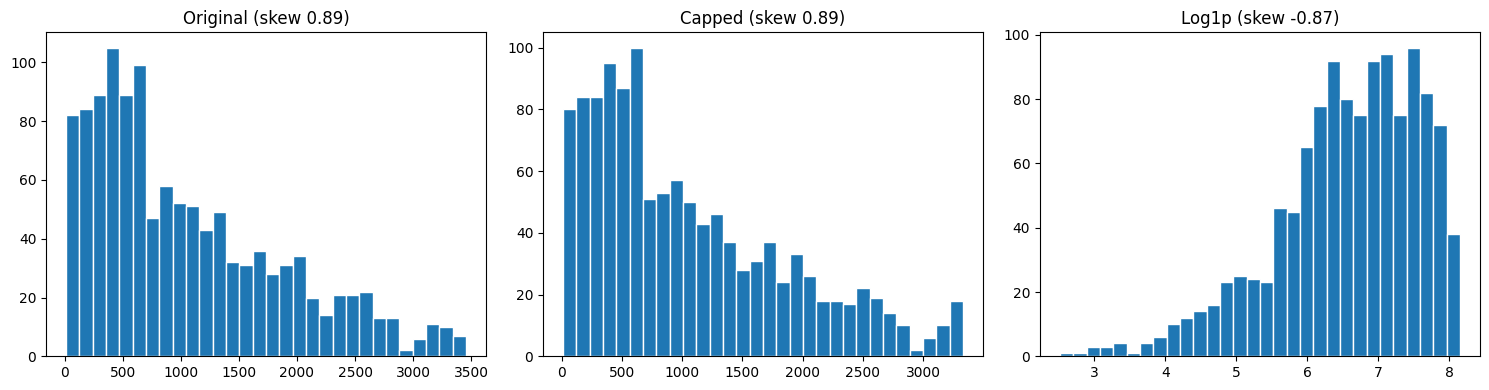

Outliers remaining after capping: 0


In [21]:
df["TotalPrice_capped"] = df["TotalPrice"].clip(lower=lo, upper=hi)
df["LogTotalPrice"] = np.log1p(df["TotalPrice"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df["TotalPrice"], bins=30, edgecolor="white");        axes[0].set_title(f"Original (skew {df['TotalPrice'].skew():.2f})")
axes[1].hist(df["TotalPrice_capped"], bins=30, edgecolor="white"); axes[1].set_title(f"Capped (skew {df['TotalPrice_capped'].skew():.2f})")
axes[2].hist(df["LogTotalPrice"], bins=30, edgecolor="white");     axes[2].set_title(f"Log1p (skew {df['LogTotalPrice'].skew():.2f})")
plt.tight_layout(); plt.show()

print("Outliers remaining after capping:",
      int(((df['TotalPrice_capped'] < lo) | (df['TotalPrice_capped'] > hi)).sum()))

## Feature engineering
- Creating at least 3 new predictive features. Each has a reason:

1.  *DaysSinceStart* - Trend over time 
2.  *CartShare* - Fraction of the cart that is this product (*Quantity / ItemsInCart*) 
3.  *IsBulkOrder* - Buying 4+ units 
4.  *HasCoupon* - Whether any coupon was used 
5.  *PriceTier* - Budget / Mid / Upper / Premium bin of unit price 
6.  *RelPriceVsProduct* - Unit price relative to that product's median price (is this a bargain or a premium item?) 
7.  *IsRepeatCustomer* - Customer appears in more than one order 

In [22]:
# Time features
df["OrderYear"]       = df["Date"].dt.year
df["OrderMonth"]      = df["Date"].dt.month
df["OrderQuarter"]    = df["Date"].dt.quarter
df["OrderDayOfWeek"]  = df["Date"].dt.dayofweek          # Mon=0
df["IsWeekend"]       = (df["OrderDayOfWeek"] >= 5).astype(int)
df["DaysSinceStart"]  = (df["Date"] - df["Date"].min()).dt.days
df["Month_sin"]       = np.sin(2 * np.pi * df["OrderMonth"] / 12)
df["Month_cos"]       = np.cos(2 * np.pi * df["OrderMonth"] / 12)

# Behavioural / ratio features
df["CartShare"]       = df["Quantity"] / df["ItemsInCart"]
df["IsBulkOrder"]     = (df["Quantity"] >= 4).astype(int)
df["HasCoupon"]       = (df["CouponCode"] != "NoCoupon").astype(int)
df["IsRepeatCustomer"] = df["CustomerID"].duplicated(keep=False).astype(int)

# Price features
df["PriceTier"] = pd.qcut(df["UnitPrice"], q=4, labels=["Budget", "Mid", "Upper", "Premium"])
df["RelPriceVsProduct"] = df["UnitPrice"] / df.groupby("Product")["UnitPrice"].transform("median")

new_feats = ["OrderYear","OrderMonth","OrderQuarter","OrderDayOfWeek","IsWeekend","DaysSinceStart",
             "Month_sin","Month_cos","CartShare","IsBulkOrder","HasCoupon","IsRepeatCustomer",
             "PriceTier","RelPriceVsProduct"]
df[new_feats].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
OrderYear,"1,200.000",NaN,NaN,NaN,"2,023.767",0.751,"2,023.000","2,023.000","2,024.000","2,024.000","2,025.000"
OrderMonth,"1,200.000",NaN,NaN,NaN,5.995,3.344,1.000,3.000,6.000,9.000,12.000
OrderQuarter,"1,200.000",NaN,NaN,NaN,2.317,1.089,1.000,1.000,2.000,3.000,4.000
OrderDayOfWeek,"1,200.000",NaN,NaN,NaN,3.051,2.026,0.000,1.000,3.000,5.000,6.000
IsWeekend,"1,200.000",NaN,NaN,NaN,0.298,0.458,0.000,0.000,0.000,1.000,1.000
DaysSinceStart,"1,200.000",NaN,NaN,NaN,446.707,265.870,0.000,214.750,447.000,677.500,911.000
Month_sin,"1,200.000",NaN,NaN,NaN,0.117,0.686,-1.000,-0.500,0.000,0.866,1.000
Month_cos,"1,200.000",NaN,NaN,NaN,-0.071,0.715,-1.000,-0.866,-0.000,0.500,1.000
CartShare,"1,200.000",NaN,NaN,NaN,0.580,0.250,0.167,0.400,0.500,0.750,1.000
IsBulkOrder,"1,200.000",NaN,NaN,NaN,0.390,0.488,0.000,0.000,0.000,1.000,1.000


**RelPriceVsProduct** uses a group median computed on the whole dataset.

## Dropping non-predictive columns and encoding categoricals
- **Drop:** `OrderID`, `TrackingNumber` (unique IDs), `CustomerID` (~1 order per customer), `ShippingAddress` (655 distinct values, no structure), raw `Date` (replaced by features).
- **One-hot encode** the remaining categoricals. `OrderStatus` is kept aside as a possible target.

In [23]:
drop_cols = ["OrderID", "TrackingNumber", "CustomerID", "ShippingAddress", "Date"]
model_df = df.drop(columns=drop_cols)

cat_to_encode = ["Product", "PaymentMethod", "CouponCode", "ReferralSource", "PriceTier"]
model_df = pd.get_dummies(model_df, columns=cat_to_encode, drop_first=True, dtype=int)

print("Shape after encoding:", model_df.shape)
model_df.dtypes.value_counts()

Shape after encoding: (1200, 40)


int64      27
float64     8
int32       4
object      1
Name: count, dtype: int64

### Choosing a target, split, then scale
Choosing a goal; the choice decides which columns must be removed to avoid leakage.

- **Classification:** predict `OrderStatus` (Cancelled / Returned / Pending / Shipped / Delivered).
- **Regression:** predict `TotalPrice_capped` → drop `Quantity`, `UnitPrice`, `TotalPrice`, `LogTotalPrice`, `CartShare`, `RelPriceVsProduct`, `PriceTier_*` (they let the model reconstruct the answer).


In [24]:
TARGET = "OrderStatus"
y = model_df[TARGET]
X = model_df.drop(columns=[TARGET])

# 'TotalPrice' (uncapped) is replaced by the capped version; keep log version as an alternative
X = X.drop(columns=["TotalPrice"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

scale_cols = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice_capped", "LogTotalPrice",
              "DaysSinceStart", "CartShare", "RelPriceVsProduct"]

scaler = StandardScaler().fit(X_train[scale_cols])        # fit on TRAIN only
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[scale_cols] = scaler.transform(X_train[scale_cols])
X_test_s[scale_cols]  = scaler.transform(X_test[scale_cols])

print("Train:", X_train_s.shape, " Test:", X_test_s.shape)
X_train_s[scale_cols].describe().loc[["mean", "std"]]

Train: (960, 38)  Test: (240, 38)


,Quantity,UnitPrice,ItemsInCart,TotalPrice_capped,LogTotalPrice,DaysSinceStart,CartShare,RelPriceVsProduct
mean,0.000,-0.000,-0.000,-0.000,0.000,-0.000,0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001


## Final quality checks and export

In [25]:
checks = {
    "No missing values (train)":  X_train_s.isna().sum().sum() == 0,
    "No missing values (test)":   X_test_s.isna().sum().sum() == 0,
    "All features numeric":       all(np.issubdtype(t, np.number) for t in X_train_s.dtypes),
    "No infinite values":         np.isfinite(X_train_s.values).all(),
    "No duplicate columns":       not X_train_s.columns.duplicated().any(),
}
for k, v in checks.items():
    print(("✔" if v else "✘"), k)

✔ No missing values (train)
✔ No missing values (test)
✔ All features numeric
✔ No infinite values
✔ No duplicate columns


In [26]:
# Full cleaned (unscaled) dataset + scaled train/test splits
model_df.to_csv("cleaned_ml_ready_dataset.csv", index=False)
X_train_s.assign(**{TARGET: y_train}).to_csv("train_scaled.csv", index=False)
X_test_s.assign(**{TARGET: y_test}).to_csv("test_scaled.csv", index=False)
print("Saved: cleaned_ml_ready_dataset.csv, train_scaled.csv, test_scaled.csv")

Saved: cleaned_ml_ready_dataset.csv, train_scaled.csv, test_scaled.csv


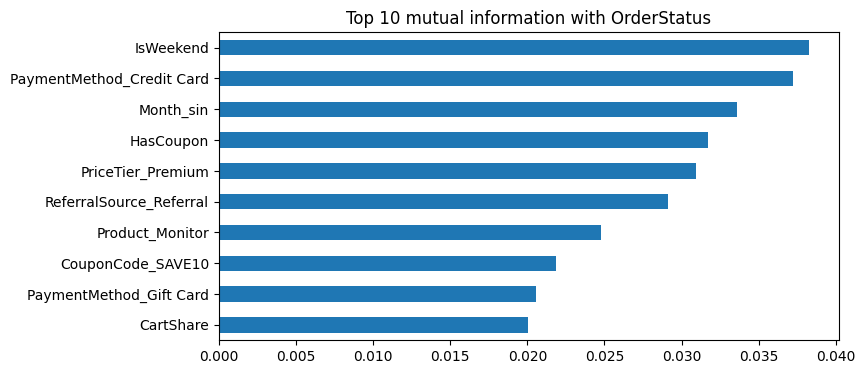

Max MI score: 0.0383 (values near 0 = almost no relationship)


In [27]:
from sklearn.feature_selection import mutual_info_classif
mi = pd.Series(mutual_info_classif(X_train_s, y_train, random_state=RANDOM_STATE), index=X_train_s.columns)
mi.sort_values(ascending=False).head(10).plot(kind="barh", title="Top 10 mutual information with OrderStatus").invert_yaxis()
plt.show()
print("Max MI score:", round(mi.max(), 4), "(values near 0 = almost no relationship)")

If the scores are all close to zero, the dataset behaves like randomly generated data: its columns are independent of the order status. That is an important *finding* to report, not a flaw in your cleaning. It means a model on this data will perform near chance (about 20% for 5 balanced classes).